# Fixing the Vanishing Gradient: Initialization and Normalization

**AIGC 5500 — Week 2, Part 2 — "Try it" exercise**

Fixes the vanishing gradient from Part 1's `DeepSigmoidNet` two ways at
once: replacing its default initialization with **Xavier initialization**
(matched to the sigmoid activation), and adding a **BatchNorm1d** layer
after every linear layer, before the sigmoid. Then it re-runs the exact
same gradient check from Part 1 and compares the two side by side.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## The network

The same architecture as Part 1's demo, but the initialization and the
presence of BatchNorm are now both configurable — so the "broken" and
"fixed" versions are the same class with two settings changed, not two
unrelated implementations.

In [2]:
class DeepSigmoidNet(nn.Module):
    """The same architecture as Part 1's demo, but the initialization
    and the presence of BatchNorm are now both configurable, so the
    "broken" and "fixed" versions are the same class with two settings
    changed — not two unrelated implementations.
    """

    def __init__(self, depth, width=32, in_features=32, use_fix=False):
        super().__init__()
        self.use_fix = use_fix

        linears = []
        norms = []
        n_in = in_features
        for _ in range(depth):
            linears.append(nn.Linear(n_in, width))
            norms.append(nn.BatchNorm1d(width) if use_fix else None)
            n_in = width
        self.linears = nn.ModuleList(linears)
        self.norms = nn.ModuleList([n for n in norms if n is not None]) if use_fix else None
        self.out = nn.Linear(width, 1)

        self._init_weights()

    def _init_weights(self):
        for layer in self.linears:
            if self.use_fix:
                # Xavier initialization, matched to sigmoid: keeps the
                # variance of activations roughly constant from layer
                # to layer, which is exactly what Part 2 says it does.
                nn.init.xavier_normal_(layer.weight)
            else:
                # Part 1's broken default: a small fixed std, unrelated
                # to the layer's fan-in/fan-out.
                nn.init.normal_(layer.weight, mean=0.0, std=0.5)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for i, linear in enumerate(self.linears):
            x = linear(x)
            if self.use_fix:
                x = self.norms[i](x)
            x = torch.sigmoid(x)
        return self.out(x)

## Running one configuration

Build the network at a given depth with `use_fix` either on or off, run
one forward and backward pass on random data, and read off the mean
absolute gradient of each linear layer's weights — exactly Part 1's
check, applied here to both versions.

In [3]:
def per_layer_grad_norms(model):
    return [layer.weight.grad.abs().mean().item() for layer in model.linears]


def run(depth, use_fix, seed=0, width=32, in_features=32, n_samples=64):
    torch.manual_seed(seed)
    model = DeepSigmoidNet(depth=depth, width=width, in_features=in_features, use_fix=use_fix)

    x = torch.randn(n_samples, in_features)
    y = torch.randn(n_samples, 1)

    preds = model(x)
    loss = nn.functional.mse_loss(preds, y)
    loss.backward()

    return per_layer_grad_norms(model)

## Run broken vs. fixed at three depths

Same three depths as Part 1 (2, 8, 20), so the improvement is measured
against the identical baseline.

In [4]:
depths = [2, 8, 20]

all_broken, all_fixed = {}, {}
for depth in depths:
    broken = run(depth, use_fix=False, seed=0)
    fixed = run(depth, use_fix=True, seed=0)
    all_broken[depth] = broken
    all_fixed[depth] = fixed

    b_first, f_first = broken[0], fixed[0]
    b_last, f_last = broken[-1], fixed[-1]
    print(f"depth {depth:>3}  |  broken layer-0 grad = {b_first:.2e}  "
          f"(last/first = {b_last / b_first:,.0f}x)  |  "
          f"fixed layer-0 grad = {f_first:.2e}  "
          f"(last/first = {f_last / f_first:,.1f}x)")

depth   2  |  broken layer-0 grad = 1.71e-03  (last/first = 2x)  |  fixed layer-0 grad = 5.35e-03  (last/first = 1.2x)
depth   8  |  broken layer-0 grad = 2.20e-05  (last/first = 56x)  |  fixed layer-0 grad = 5.57e-03  (last/first = 0.7x)
depth  20  |  broken layer-0 grad = 3.55e-09  (last/first = 1,089,995x)  |  fixed layer-0 grad = 6.02e-03  (last/first = 0.6x)


Read the `last/first` ratio in each pair: for the broken network it
grows explosively with depth (this is Part 1's vanishing-gradient
signature). For the fixed network it stays close to 1 at every depth —
the layer closest to the input has a gradient in the same ballpark as
the layer closest to the loss.

## Full per-layer comparison at depth 20

The depth where the broken version is at its worst.

In [5]:
def print_comparison(depth, broken, fixed):
    print(f"Depth = {depth}")
    print(f"{'Layer':>7} | {'Broken (Part 1)':>18} | {'Fixed (Part 2)':>16}")
    print("-" * 48)
    for i in range(len(broken)):
        print(f"{i:>7} | {broken[i]:>18.2e} | {fixed[i]:>16.2e}")

    b_first, f_first = broken[0], fixed[0]
    print(f"\nLayer-0 gradient — broken: {b_first:.2e}   fixed: {f_first:.2e}")
    if b_first > 0:
        print(f"Xavier init + BatchNorm recovered {f_first / b_first:,.0f}x more gradient at layer 0.")

print_comparison(20, all_broken[20], all_fixed[20])

Depth = 20
  Layer |    Broken (Part 1) |   Fixed (Part 2)
------------------------------------------------
      0 |           3.55e-09 |         6.02e-03
      1 |           1.08e-08 |         5.81e-03
      2 |           2.04e-08 |         5.76e-03
      3 |           7.84e-08 |         6.39e-03
      4 |           1.14e-07 |         5.67e-03
      5 |           2.11e-07 |         5.38e-03
      6 |           4.35e-07 |         6.11e-03
      7 |           1.02e-06 |         6.99e-03
      8 |           2.26e-06 |         5.53e-03
      9 |           3.74e-06 |         5.64e-03
     10 |           7.99e-06 |         4.88e-03
     11 |           1.68e-05 |         4.70e-03
     12 |           2.62e-05 |         5.51e-03
     13 |           5.76e-05 |         5.51e-03
     14 |           1.38e-04 |         5.31e-03
     15 |           2.86e-04 |         5.27e-03
     16 |           4.10e-04 |         3.68e-03
     17 |           1.05e-03 |         4.17e-03
     18 |           1.65e-03

## Plot it

One flat line, one line climbing several orders of magnitude — the
clearest version of the "no longer shrinks by an order of magnitude per
layer" result Part 2's Try it asks you to confirm.

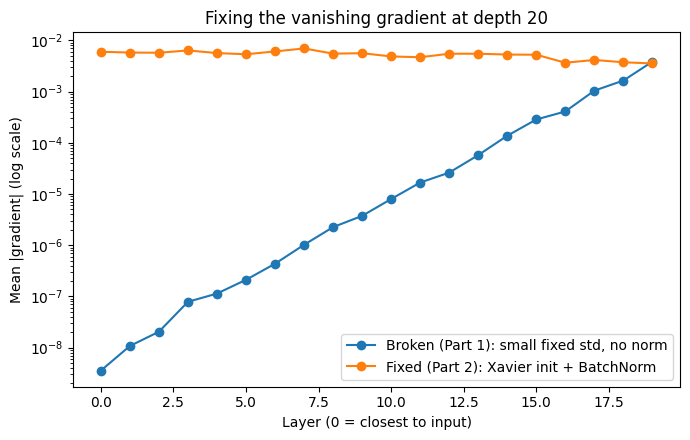

In [6]:
broken, fixed = all_broken[20], all_fixed[20]
x = list(range(len(broken)))

plt.figure(figsize=(7, 4.5))
plt.plot(x, broken, marker="o", label="Broken (Part 1): small fixed std, no norm")
plt.plot(x, fixed, marker="o", label="Fixed (Part 2): Xavier init + BatchNorm")
plt.yscale("log")
plt.xlabel("Layer (0 = closest to input)")
plt.ylabel("Mean |gradient| (log scale)")
plt.title("Fixing the vanishing gradient at depth 20")
plt.legend()
plt.tight_layout()
plt.savefig("initialization_normalization_fix.png", dpi=150)
plt.show()

## Takeaway

Xavier initialization keeps each layer's output variance close to its
input variance at the start of training, and BatchNorm keeps it there
as training proceeds — together they stop the chain-rule product from
Week 1 from shrinking geometrically with depth. Neither tool changes
the architecture or the data; both only change the *scale* activations
and gradients are allowed to drift to, which turns out to be enough to
take a completely untrainable 20-layer network back to one whose
input-side layers learn at roughly the same rate as its output-side
layers.